# Stroke Classification and SHAP Explanation

Tasks 1–6. This executed companion notebook reads the verified run outputs and displays the evidence. The complete model and explainer implementation is in `code/run_assignment.py`. Set `REGENERATE = True` below to repeat the full experiment. The outcome is recorded stroke status, not a validated future risk.

In [1]:
from pathlib import Path
import json
import subprocess
import sys
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / 'code/run_assignment.py').exists():
    ROOT = ROOT / 'submission'
assert (ROOT / 'code/run_assignment.py').exists()
OUTPUT = ROOT / 'outputs'
REGENERATE = False
if REGENERATE or not (OUTPUT / 'run_details.json').exists():
    subprocess.run([sys.executable, str(ROOT / 'code/run_assignment.py')], check=True)
details = json.loads((OUTPUT / 'run_details.json').read_text())
metrics = json.loads((OUTPUT / 'metrics.json').read_text())
print('Recorded environment:', details['environment'])
print('Data SHA256:', details['data_sha256'])

Recorded environment: {'python': '3.12.14 (main, Aug 25 2026, 13:50:33) [Clang 22.1.3 ]', 'platform': 'macOS-26.5.1-arm64-arm-64bit', 'packages': {'numpy': '2.2.6', 'pandas': '2.2.3', 'scipy': '1.16.3', 'scikit-learn': '1.7.2', 'shap': '0.49.1', 'imbalanced-learn': '0.14.0', 'matplotlib': '3.10.7', 'numba': '0.68.1', 'joblib': '1.6.0'}}
Data SHA256: 644d473b05d2797006bd94865e4f8bb057f0c721617911613c82c8fcfc707420


## Task 1 Exploratory data analysis
The original teaching script was executed unchanged using a CSV-path and figure-saving adapter. All 12 original histograms and its console log are retained under `outputs/eda`. The modelling pipeline uses a training-only median imputer instead of the teaching script’s zero imputation.

Rows and columns: [5110, 12]
Class counts: {'0': 4861, '1': 249}
Missing values: {'id': 0, 'gender': 0, 'age': 0, 'hypertension': 0, 'heart_disease': 0, 'ever_married': 0, 'work_type': 0, 'Residence_type': 0, 'avg_glucose_level': 0, 'bmi': 201, 'smoking_status': 0, 'stroke': 0}
Unavailable smoking status: 1544
Original script executed: True
Original histograms saved: 12


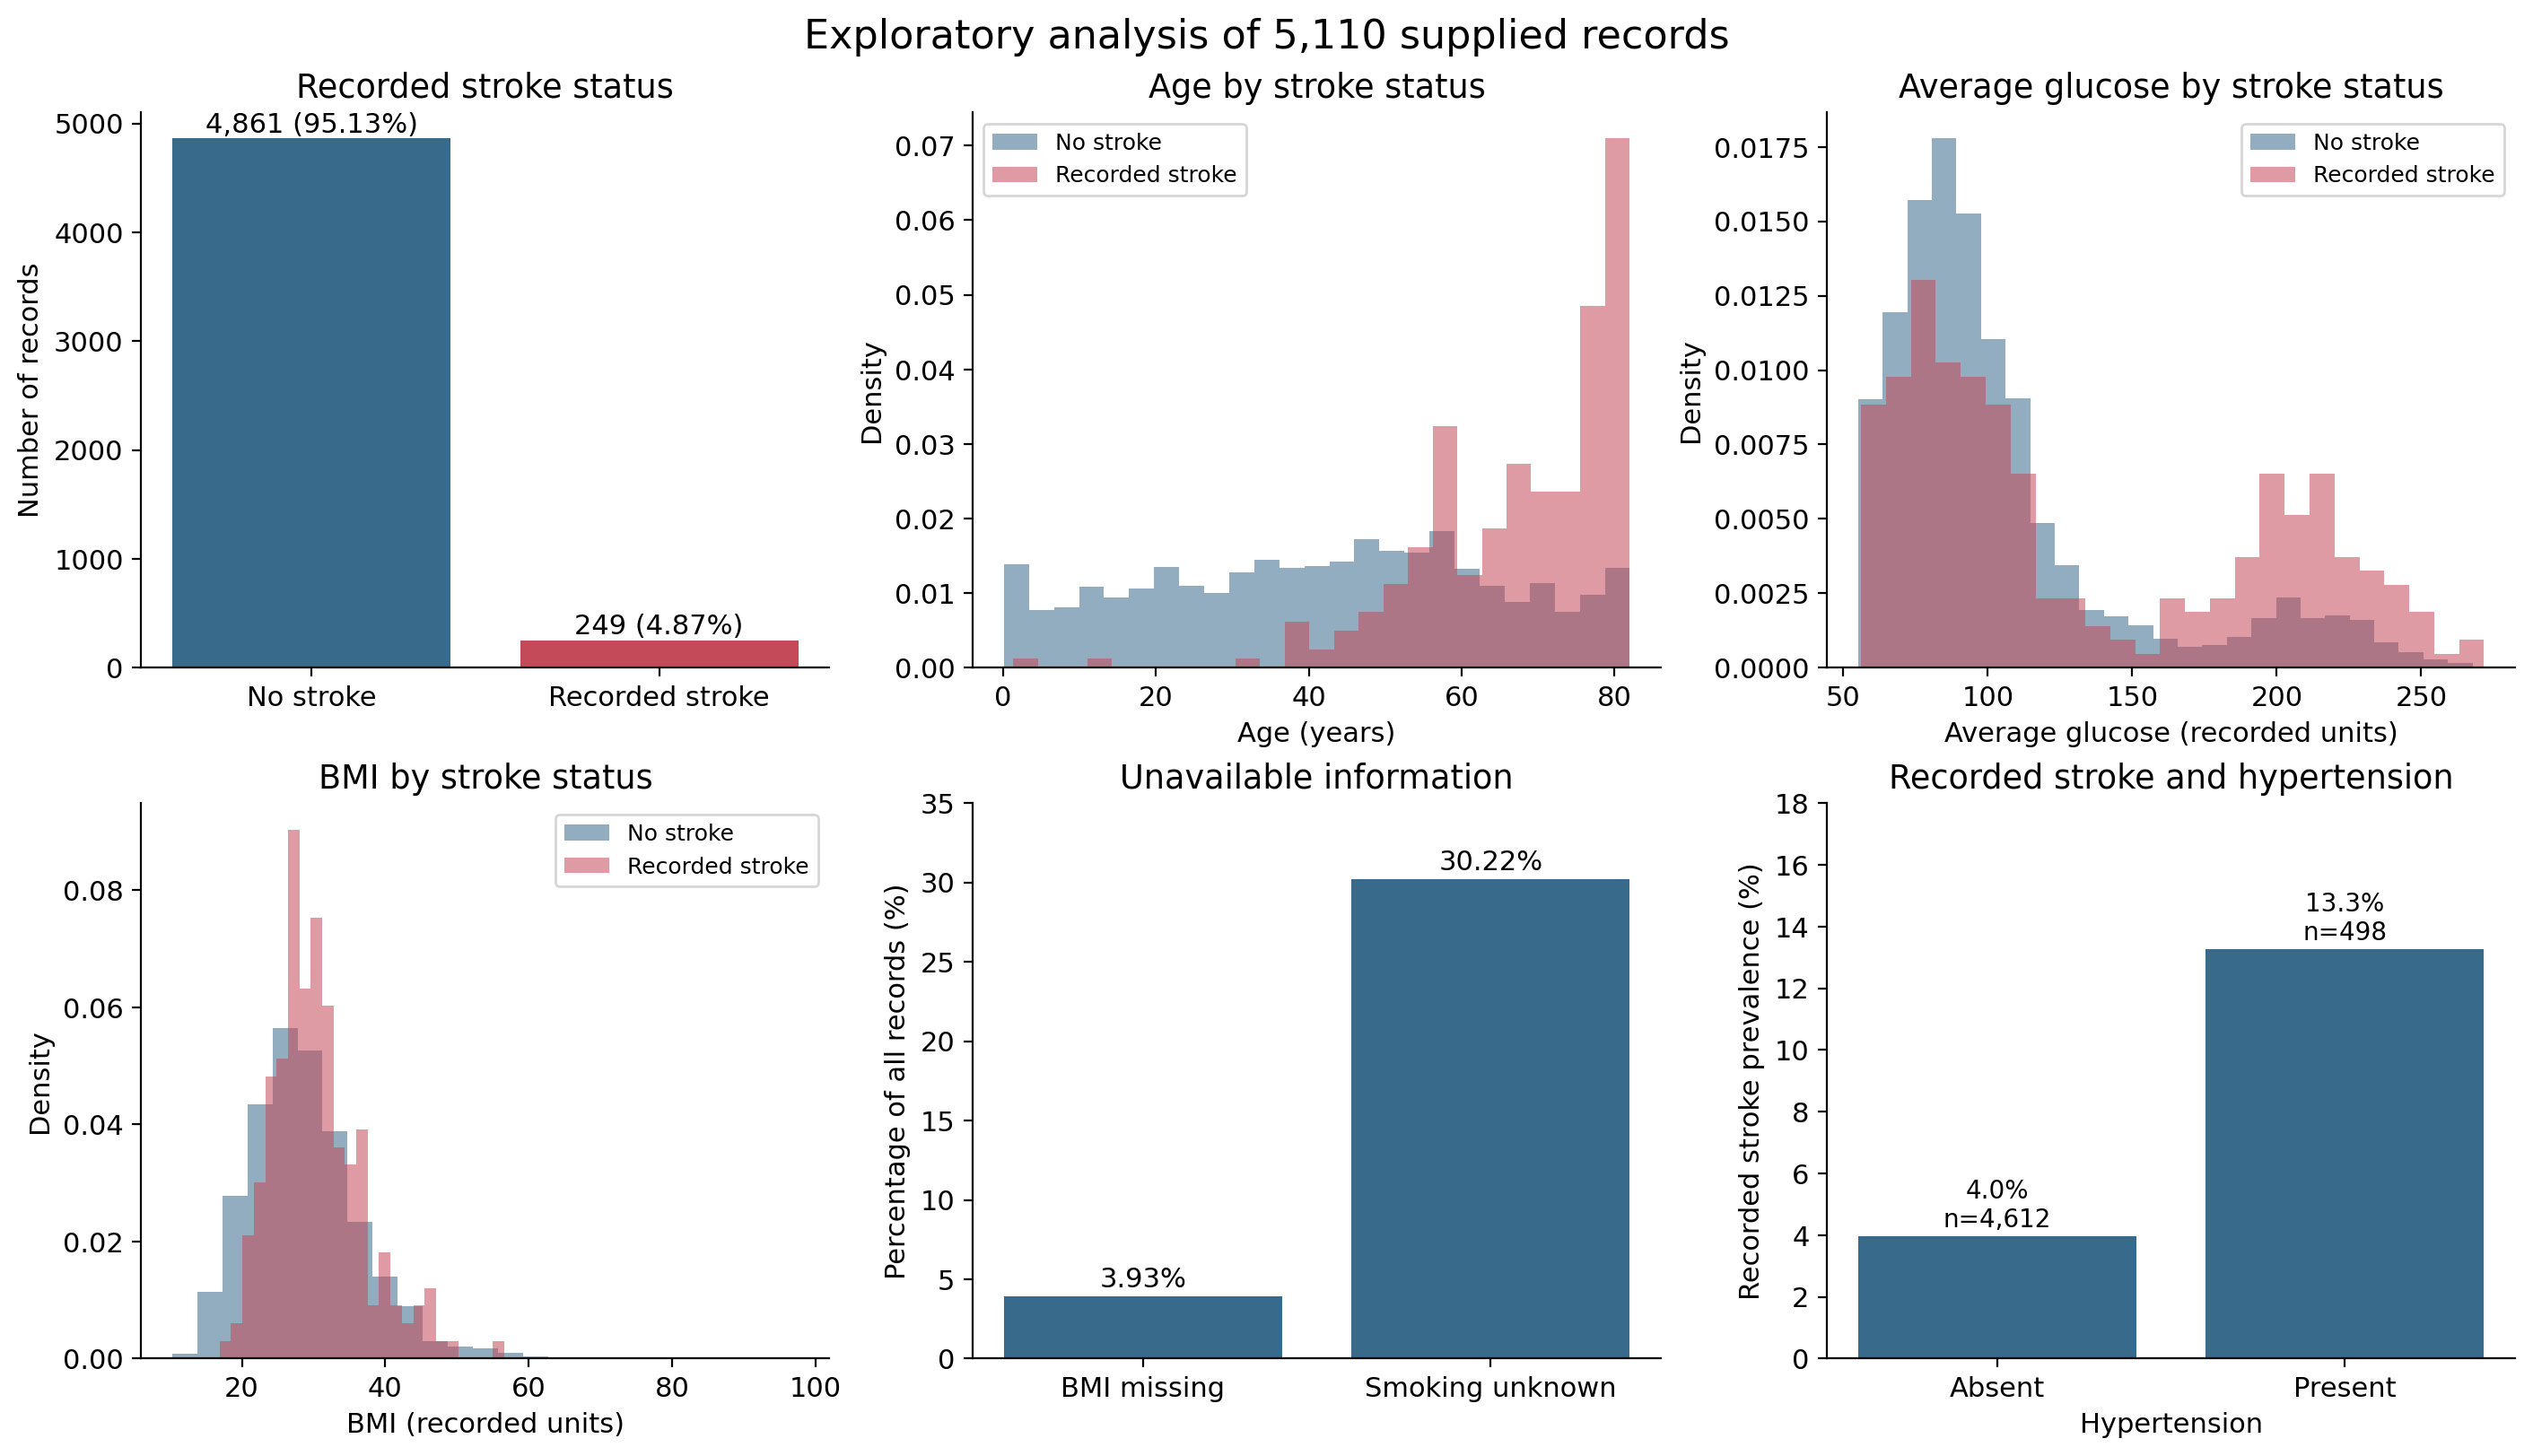

,Unnamed: 0,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,count,5110.000000,5110,5110.000000,5110.000000,5110.000000,5110,5110,5110,5110.000000,4909.000000,5110,5110.000000
1,unique,NaN,3,NaN,NaN,NaN,2,5,2,NaN,NaN,4,NaN
2,top,NaN,Female,NaN,NaN,NaN,Yes,Private,Urban,NaN,NaN,never smoked,NaN
3,freq,NaN,2994,NaN,NaN,NaN,3353,2925,2596,NaN,NaN,1892,NaN
4,mean,36517.829354,NaN,43.226614,0.097456,0.054012,NaN,NaN,NaN,106.147677,28.893237,NaN,0.048728
5,std,21161.721625,NaN,22.612647,0.296607,0.226063,NaN,NaN,NaN,45.283560,7.854067,NaN,0.215320
6,min,67.000000,NaN,0.080000,0.000000,0.000000,NaN,NaN,NaN,55.120000,10.300000,NaN,0.000000
7,25%,17741.250000,NaN,25.000000,0.000000,0.000000,NaN,NaN,NaN,77.245000,23.500000,NaN,0.000000
8,50%,36932.000000,NaN,45.000000,0.000000,0.000000,NaN,NaN,NaN,91.885000,28.100000,NaN,0.000000
9,75%,54682.000000,NaN,61.000000,0.000000,0.000000,NaN,NaN,NaN,114.090000,33.100000,NaN,0.000000


In [2]:
eda = json.loads((OUTPUT / 'eda/eda.json').read_text())
print('Rows and columns:', eda['shape'])
print('Class counts:', eda['class_counts'])
print('Missing values:', eda['missing'])
print('Unavailable smoking status:', eda['unknown_smoking'])
print('Original script executed:', eda['original_script_executed'])
print('Original histograms saved:', eda['original_figure_count'])
display(Image(filename=str(OUTPUT / 'eda/eda_panel.png')))
display(pd.read_csv(OUTPUT / 'eda/descriptive_statistics.csv'))

## Task 2 Random forest and Tree SHAP
The forest has 200 trees, depth at most 8 and leaf size at least 5. Balanced subsample weights handle training imbalance. The 0.52 threshold is selected using validation positive F1. Tree SHAP uses weighted training paths. For this random forest, raw outputs equal class probabilities. Class 1 is selected explicitly.

Split counts: {'train': {'n': 3066, 'positive': 149}, 'validation': {'n': 1022, 'positive': 50}, 'test': {'n': 1022, 'positive': 50}}


,model,threshold,accuracy,balanced_accuracy,precision,recall,f1,macro_f1,roc_auc,average_precision,brier,tn,fp,fn,tp,n,positive_support,prevalence
0,random_forest,0.52,0.87182,0.704959,0.195489,0.52,0.284153,0.606880,0.864568,0.221746,0.098549,865,107,24,26,1022,50,0.048924
1,neural_network,0.04,0.85225,0.561872,0.096000,0.24,0.137143,0.528175,0.703230,0.129947,0.093216,859,113,38,12,1022,50,0.048924


Always-negative test baseline: {'threshold': 0.5, 'accuracy': 0.9510763209393346, 'balanced_accuracy': 0.5, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'macro_f1': 0.48746238716148443, 'roc_auc': 0.5, 'average_precision': 0.04892367906066536, 'brier': 0.04892367906066536, 'tn': 972, 'fp': 0, 'fn': 50, 'tp': 0, 'n': 1022, 'positive_support': 50, 'prevalence': 0.04892367906066536}
Class index: 1
Transformed feature count: 21
Tree SHAP base: 0.5000000000000003
Maximum reconstruction residual: 4.229255834431456e-15


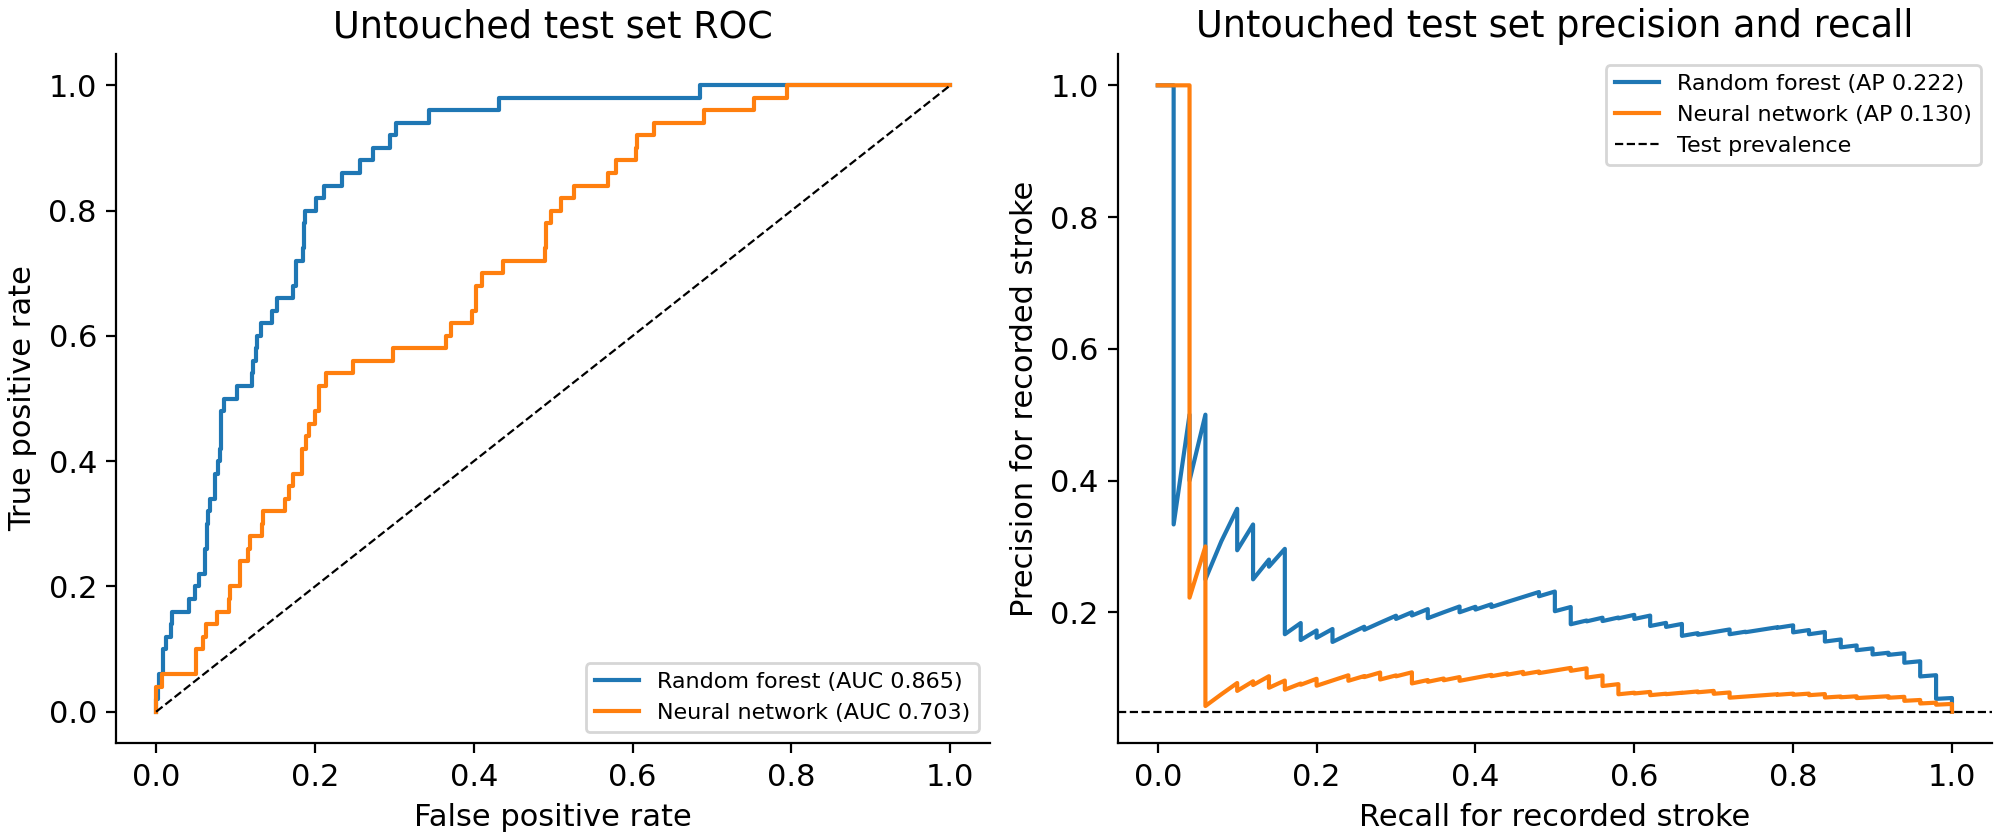

In [3]:
print('Split counts:', details['split_counts'])
display(pd.read_csv(OUTPUT / 'tables/model_metrics.csv'))
print('Always-negative test baseline:', metrics['always_negative'])
print('Class index:', metrics['random_forest']['positive_class_index'])
print('Transformed feature count:', len(details['preprocessor_feature_names']))
print('Tree SHAP base:', details['tree_base'])
print('Maximum reconstruction residual:', details['tree_max_residual'])
display(Image(filename=str(OUTPUT / 'figures/performance_curves.png')))

## Task 3 Local force plot
The case is the first stroke-positive record in the stored stratified explanation sample, selected without inspecting correctness. Row 18 is a false negative. A readable explanation does not establish that the classification is correct.

Source row (zero based): 18
Recorded stroke: 1
Raw inputs: {'age': 60.0, 'avg_glucose_level': 89.22, 'bmi': 37.8, 'hypertension': 0, 'heart_disease': 0, 'gender': 'Female', 'ever_married': 'No', 'work_type': 'Private', 'Residence_type': 'Urban', 'smoking_status': 'never smoked'}
Score: 0.33760319621261764 threshold: 0.52
Base + contributions = 0.33760319621262114


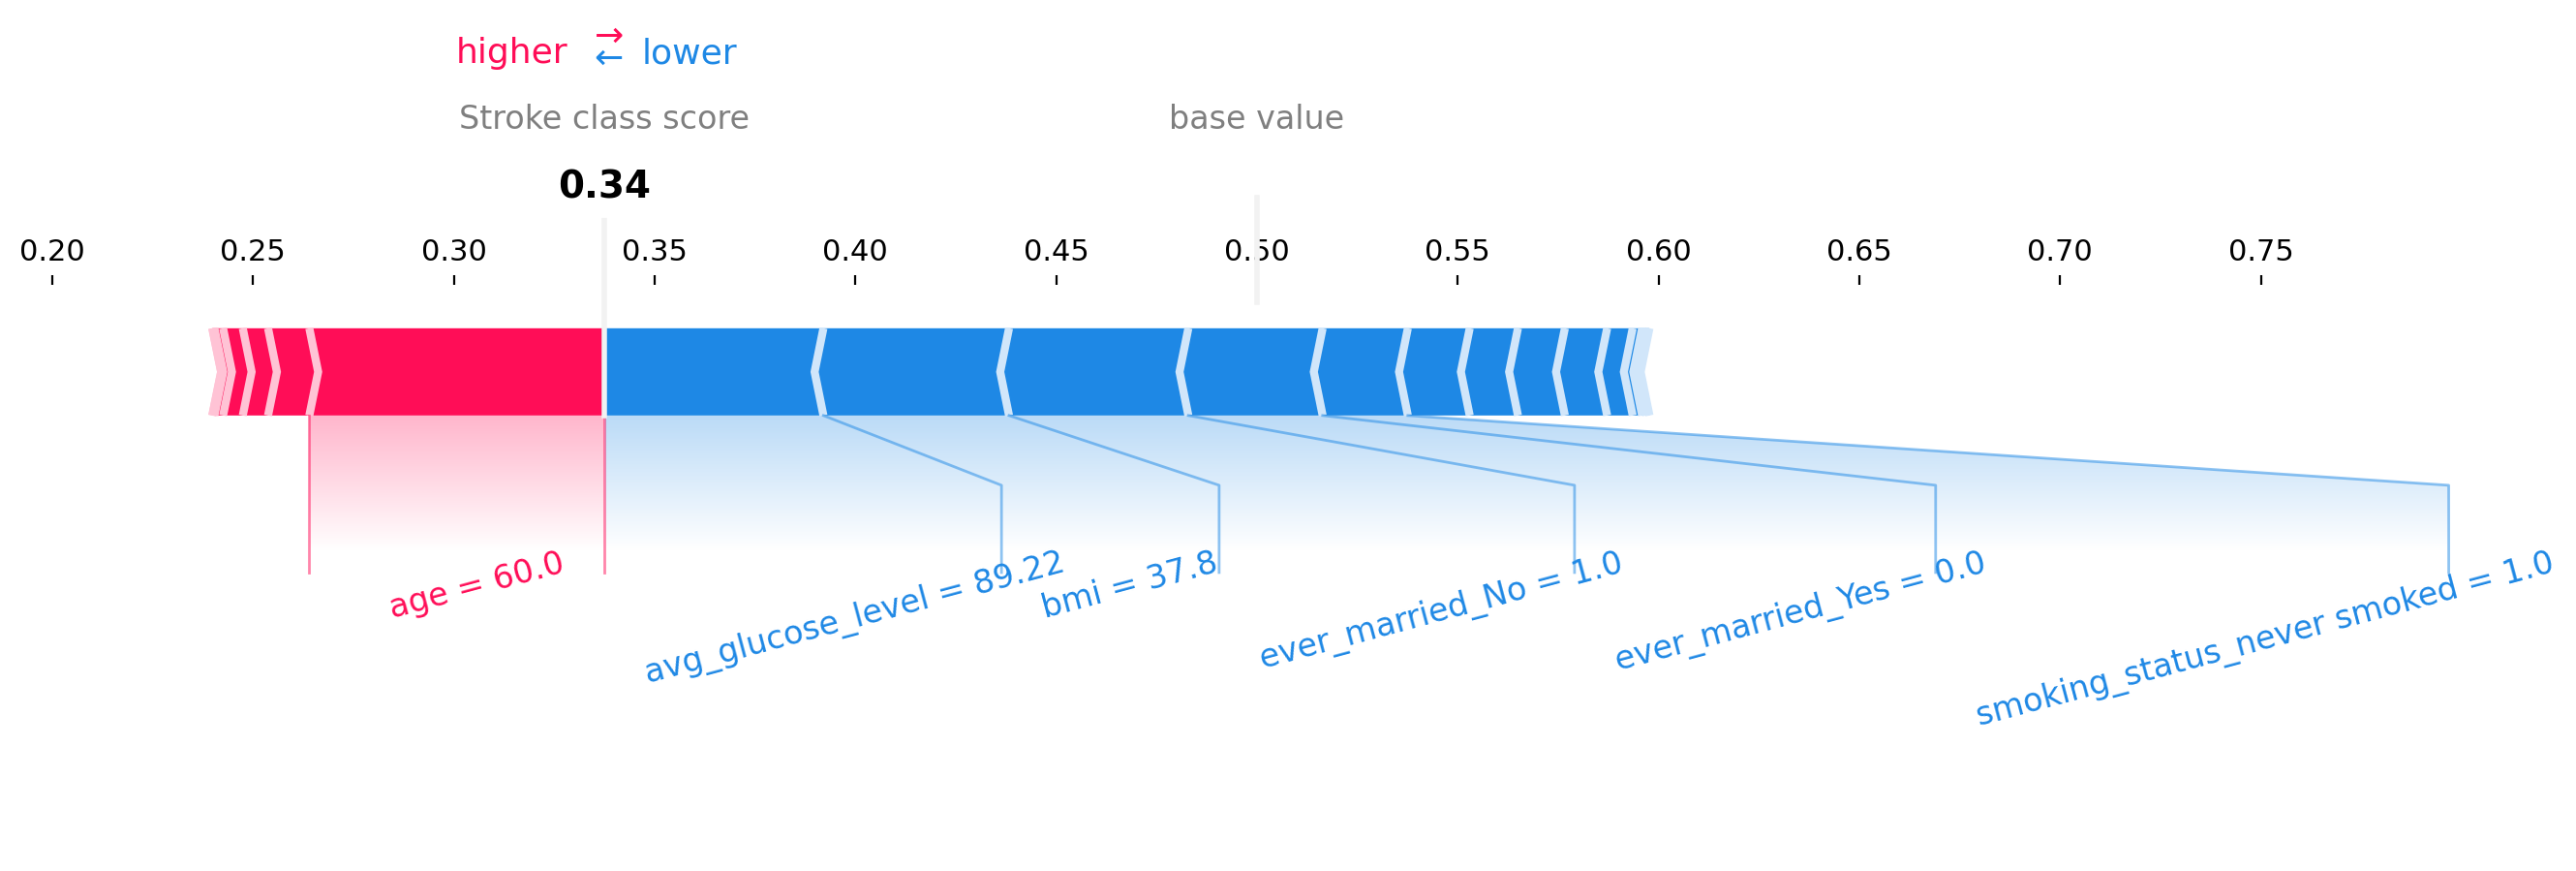

,feature,value,shap_value
0,ever_married,No,-0.078096
1,age,60.0,0.073573
2,avg_glucose_level,89.22,-0.054448
3,bmi,37.8,-0.046217
4,smoking_status,never smoked,-0.030944
5,work_type,Private,-0.018417
6,Residence_type,Urban,0.016569
7,hypertension,0,-0.015403
8,heart_disease,0,-0.011684
9,gender,Female,0.002670


Interactive plot: /Users/pangpang/Curriculum/7009 周日11-2/assignment1/submission/outputs/figures/tree_force.html


In [4]:
case = details['case']
print('Source row (zero based):', case['row_index'])
print('Recorded stroke:', case['actual'])
print('Raw inputs:', case['raw_features'])
print('Score:', case['tree_score'], 'threshold:', metrics['random_forest']['test']['threshold'])
print('Base + contributions =', details['tree_base'] + case['tree_sum'])
display(Image(filename=str(OUTPUT / 'figures/tree_force.png')))
display(pd.read_csv(OUTPUT / 'tables/tree_local_contributions.csv'))
print('Interactive plot:', OUTPUT / 'figures/tree_force.html')

## Task 4 Global summary plot
The beeswarm displays encoded columns. The table groups signed dummy contributions within each record before averaging their absolute values. The explanation cohort contains 120 test records, including six strokes.

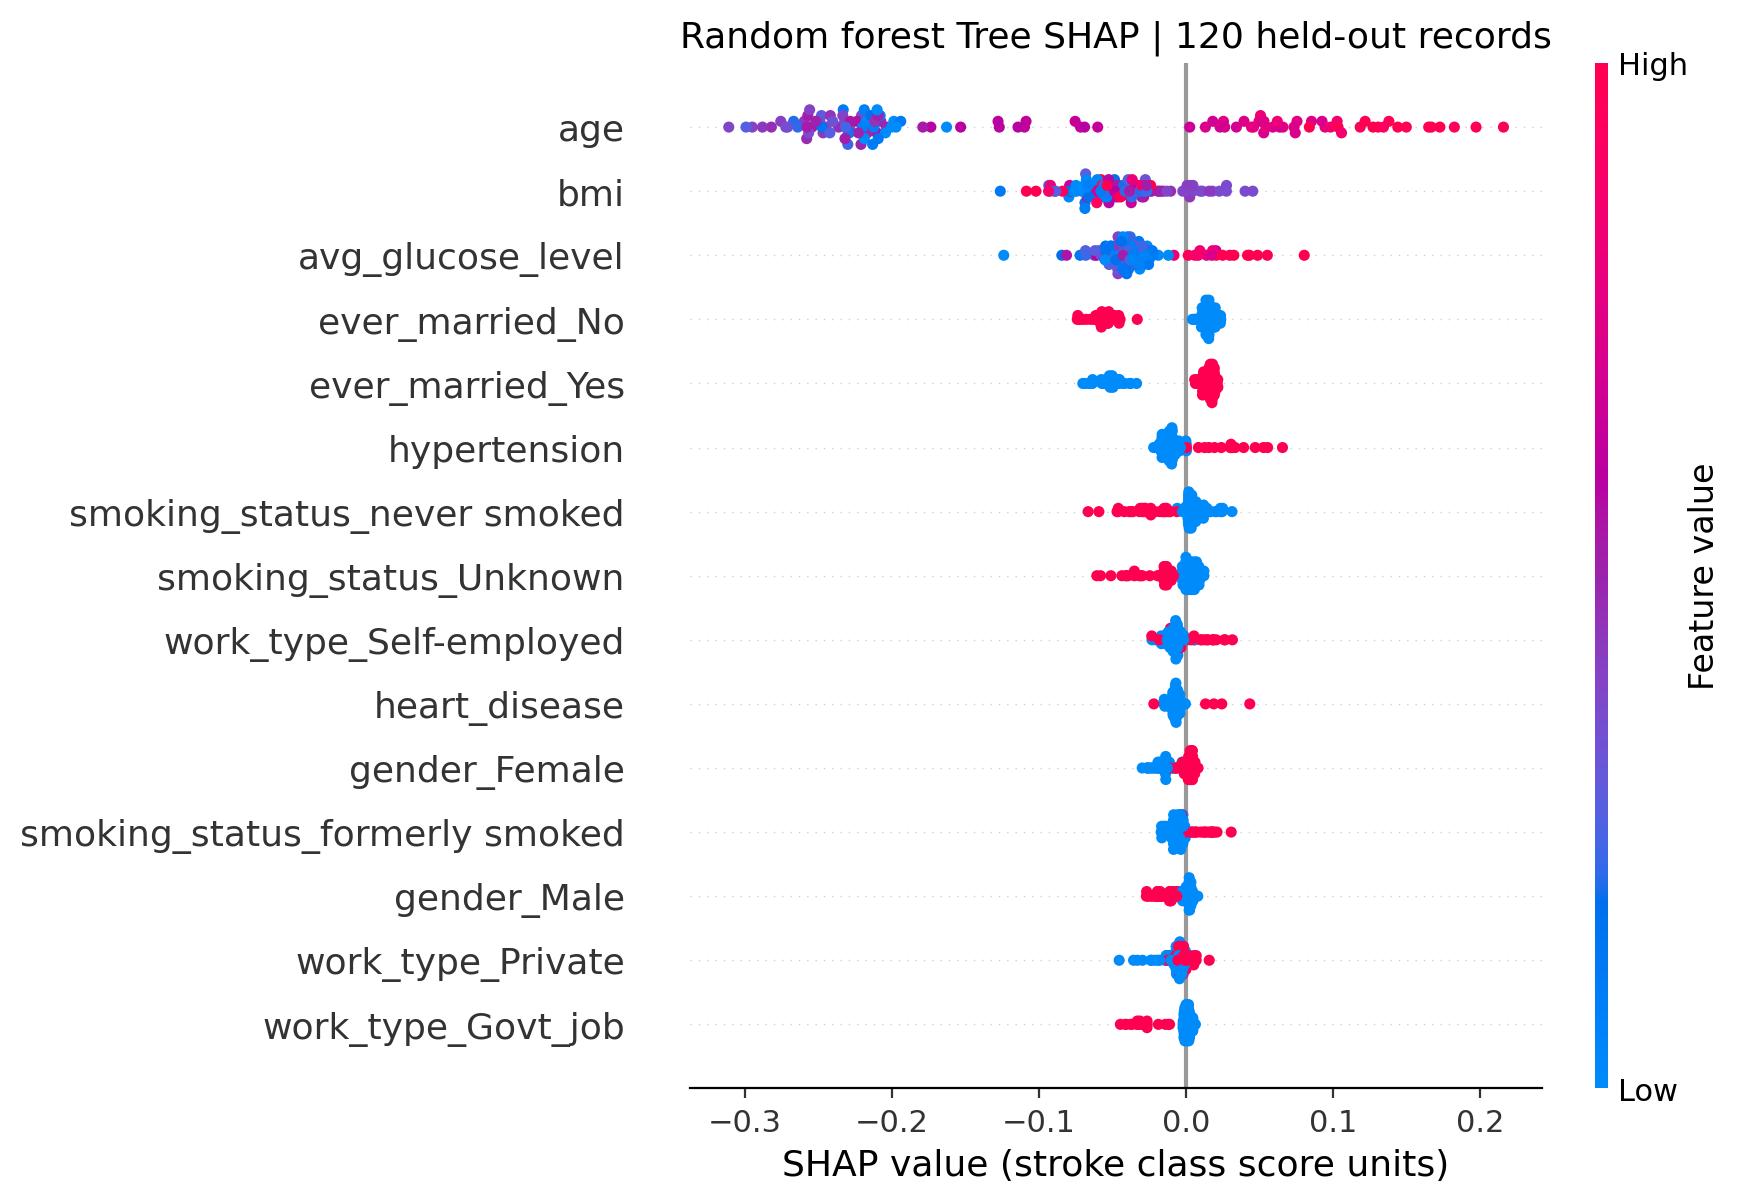

,feature,mean_abs_shap
0,age,0.169538
1,ever_married,0.056126
2,bmi,0.047677
3,avg_glucose_level,0.040362
4,smoking_status,0.026460
5,work_type,0.021346
6,gender,0.014698
7,hypertension,0.013811
8,Residence_type,0.008580
9,heart_disease,0.008057


Explanation n: 120 ; positive n: 6


In [5]:
display(Image(filename=str(OUTPUT / 'figures/tree_summary.png')))
display(pd.read_csv(OUTPUT / 'tables/tree_global_importance.csv'))
print('Explanation n:', details['explanation_sample_size'], '; positive n:', details['explanation_positive_count'])

## Task 5 Three audience slides
`Stroke_SHAP_Audience_Slides.pptx` contains exactly three slides: a data scientist, a doctor and a patient. The same forest, case, score and threshold are used throughout. Patient language describes model behaviour without causal or future-risk claims.

In [6]:
from zipfile import ZipFile
import re
slide_file = ROOT / 'Stroke_SHAP_Audience_Slides.pptx'
with ZipFile(slide_file) as z:
    slides = [n for n in z.namelist() if re.fullmatch(r'ppt/slides/slide\d+\.xml', n)]
print('Slide file:', slide_file.name)
print('Total slides:', len(slides))
assert len(slides) == 3

Slide file: Stroke_SHAP_Audience_Slides.pptx
Total slides: 3


## Task 6 A different neural network with Kernel SHAP
A multilayer perceptron uses hidden layers (32, 16), training-only standardisation and random oversampling. It reaches its 600-iteration limit. Kernel SHAP explains the complete pipeline with 100 original training background rows, 512 coalition samples, ten original-variable coalitions and an identity link. Category codes are reversed before model preprocessing. The warnings and weak test recall are retained as limitations.

Neural-network test metrics: {'threshold': 0.04, 'accuracy': 0.8522504892367906, 'balanced_accuracy': 0.5618724279835391, 'precision': 0.096, 'recall': 0.24, 'f1': 0.13714285714285715, 'macro_f1': 0.528175494917068, 'roc_auc': 0.7032304526748971, 'average_precision': 0.12994747746789295, 'brier': 0.0932159570681671, 'tn': 859, 'fp': 113, 'fn': 38, 'tp': 12, 'n': 1022, 'positive_support': 50, 'prevalence': 0.04892367906066536}
Iterations: 600
Training warnings: ["Stochastic Optimizer: Maximum iterations (600) reached and the optimization hasn't converged yet.", 'divide by zero encountered in matmul', 'invalid value encountered in matmul', 'overflow encountered in matmul']
Kernel SHAP base: 0.04623646550195552
Kernel reconstruction residual: 5.551115123125783e-16
Local full-enumeration difference: 0.005357789138222935
Second-background local sensitivity: {'kernel': {'original_top3': ['work_type', 'Residence_type', 'hypertension'], 'second_top3': ['work_type', 'hypertension', 'Residence_t

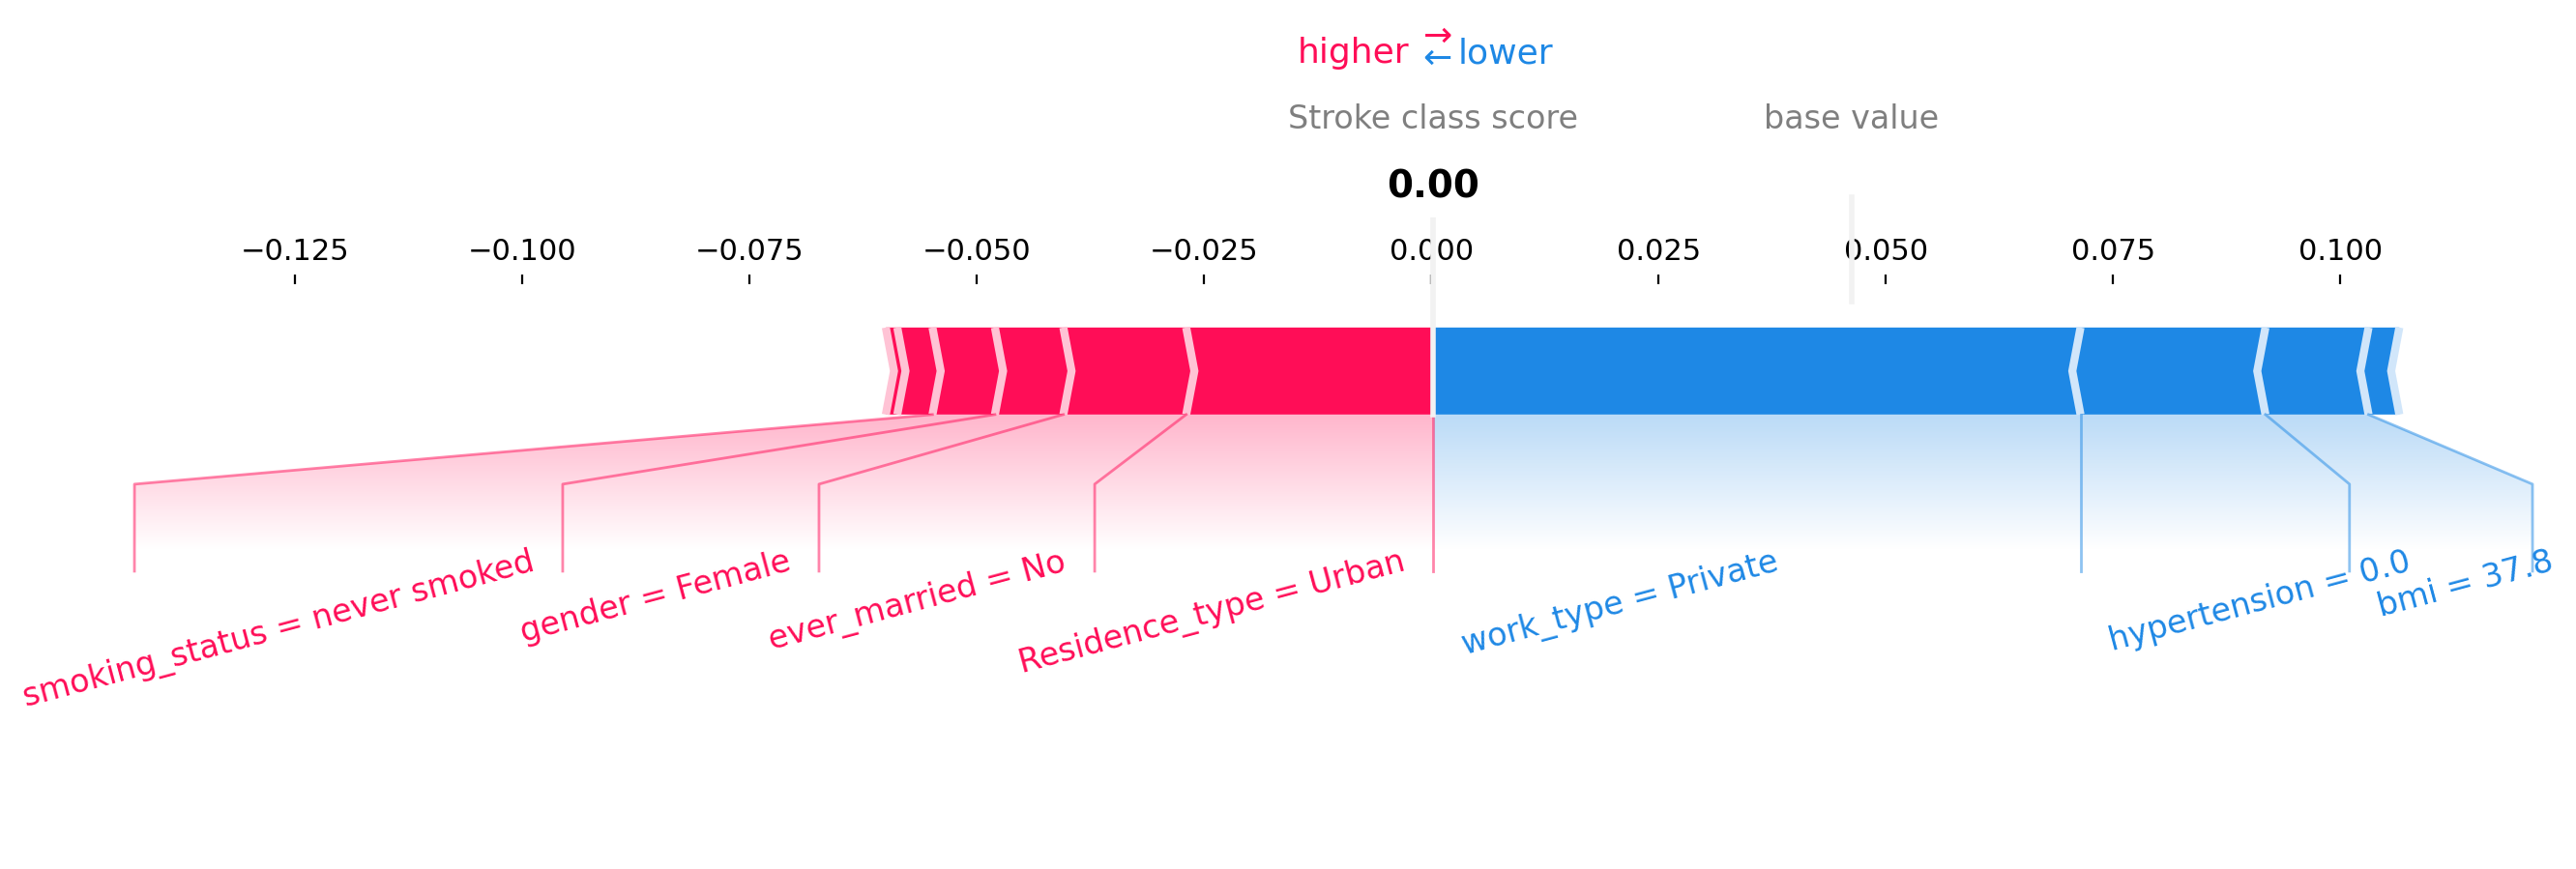

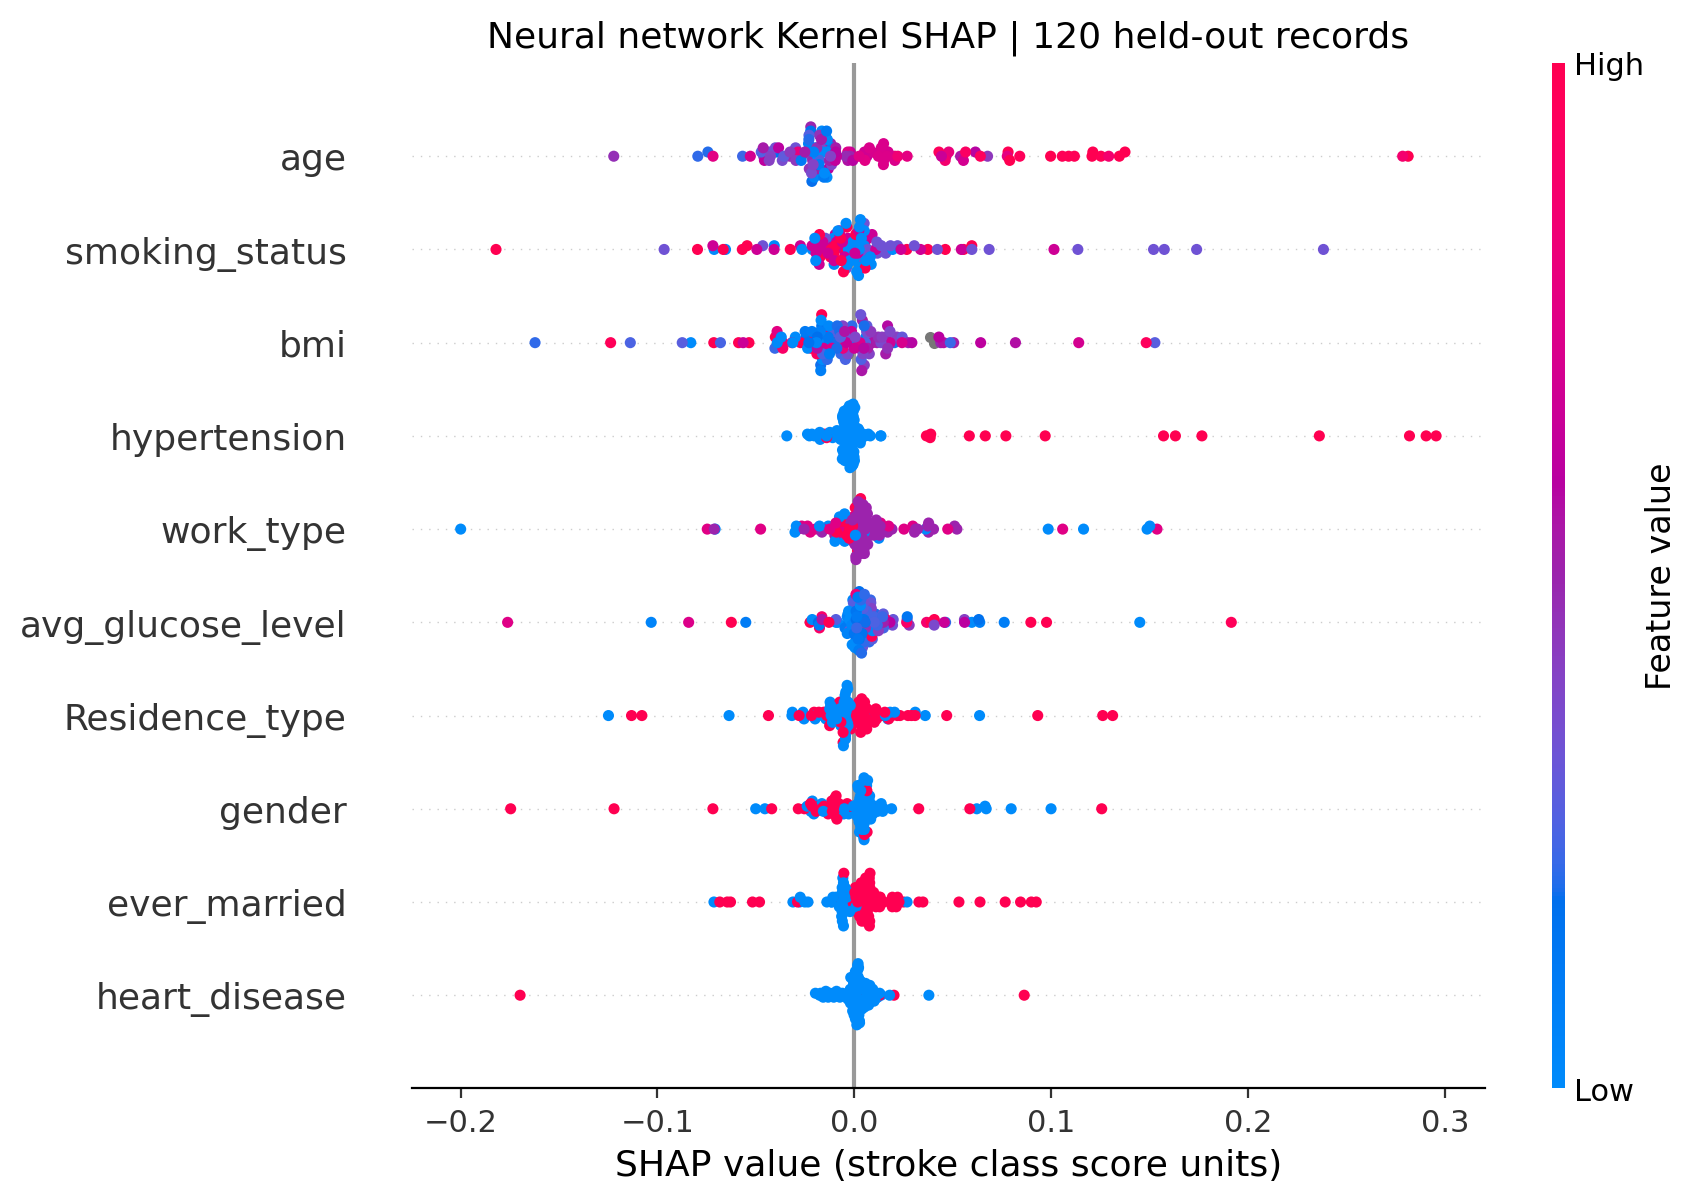

,feature,mean_abs_shap
0,age,0.040456
1,smoking_status,0.026923
2,bmi,0.026416
3,hypertension,0.021827
4,work_type,0.020812
5,avg_glucose_level,0.019912
6,Residence_type,0.016964
7,gender,0.016796
8,ever_married,0.015171
9,heart_disease,0.007407


In [7]:
print('Neural-network test metrics:', metrics['neural_network']['test'])
print('Iterations:', details['mlp_iterations'])
print('Training warnings:', details['mlp_warnings'])
print('Kernel SHAP base:', details['kernel_base'])
print('Kernel reconstruction residual:', details['kernel_max_residual'])
print('Local full-enumeration difference:', details['kernel_local_max_abs_sampling_difference'])
print('Second-background local sensitivity:', details['stability'])
display(Image(filename=str(OUTPUT / 'figures/kernel_force.png')))
display(Image(filename=str(OUTPUT / 'figures/kernel_summary.png')))
display(pd.read_csv(OUTPUT / 'tables/kernel_global_importance.csv'))

## Independent checks and conclusion
The forest performs better for the reported metrics, but still misses 24 of 50 test strokes. Both models miss the selected case. SHAP reconstruction is a mathematical consistency check, not clinical validation. The verification below reloads saved model pipelines and checks actual predictions against the stored evidence.

In [8]:
result = subprocess.run([sys.executable, str(ROOT / 'code/verify_outputs.py')], capture_output=True, text=True, check=True)
print(result.stdout)
assert result.returncode == 0

PASS: data fingerprint, all split memberships, saved predictions, confusion matrices, F1, both SHAP reconstructions, grouped contributions, local case and 12 original EDA figures



## Sources
1. fedesoriano, Stroke Prediction Dataset: https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset
2. Teaching repository: https://github.com/deepfindr/xai-series
3. Lundberg and Lee (2017), A Unified Approach to Interpreting Model Predictions: https://arxiv.org/abs/1705.07874
4. TreeExplainer: https://shap.readthedocs.io/en/stable/generated/shap.TreeExplainer.html
5. KernelExplainer: https://shap.readthedocs.io/en/stable/generated/shap.KernelExplainer.html

The supplied teaching sources are retained. OpenAI Codex assisted implementation, analysis and writing; review and disclose according to course policy.